# 6.4 The Transformer Block

**Module 6 · Note 4**

In Note 6.3 we built multi-head causal self-attention, the part of a Transformer where tokens exchange information. But attention on its own is not a Transformer layer. Every Transformer stacks a repeated unit, the **Transformer block**, and attention is only one of its four ingredients. The other three (a feed-forward network, residual connections and layer normalisation) are less glamorous, but without them a deep Transformer would not train at all.

This note assembles the block, explains what each ingredient contributes, and then puts two of them to the test. We will see what happens to a 6-block model when its residual connections are removed, and we will reproduce one of the most important practical discoveries about Transformers: that *where* you put layer normalisation decides whether a deep model trains or collapses.

**Key question:** *What is inside a Transformer block, and why does each part matter?*

**By the end of this note you will be able to:**
- describe the four ingredients of a Transformer block and the job of each;
- explain what the feed-forward network does and why it works on each token separately;
- explain how residual connections help information and gradients flow, with measurements;
- compute layer normalisation by hand;
- explain the difference between post-norm and pre-norm blocks, and show why it matters in training;
- explain why stacking blocks increases what a model can represent.

**Before you start:** read Note 6.3. You should be comfortable with the training loop and with reading loss curves (Module 3).

### Setup

Run this cell first. Most of this note runs instantly. The training experiments in Sections 6 and 7 take about two minutes in total on a CPU.

In [1]:
import os, math, time, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
torch.manual_seed(0)
print("PyTorch", torch.__version__)

PyTorch 2.14.1+cu130


## 1. The Big Picture: How a Transformer Block Works

A Transformer block takes a sequence of token vectors and returns a sequence of the same shape, `(batch, tokens, d_model)`, with each vector improved. It does that in two **sub-layers**, each wrapped in the same pattern:

1. **Attention sub-layer:** normalise the vectors, let tokens exchange information with multi-head self-attention, and **add** the result back to the input.
2. **Feed-forward sub-layer:** normalise again, process each token separately with a small two-layer network, and **add** the result back.

So the four ingredients are **multi-head self-attention**, a **feed-forward network**, **residual connections** (the "add back" steps) and **layer normalisation** (the "normalise" steps). In code, the modern version of the block is just two lines:

```
x = x + attention(layer_norm_1(x))
x = x + feed_forward(layer_norm_2(x))
```

> 🖼 *IMAGE 6.4.1 — Anatomy of a Transformer Block.* A vertical diagram on a white background, read bottom to top. A thick grey vertical arrow, labelled "residual stream x", runs straight up the full height on the left. Two branches leave it to the right and rejoin it. Lower branch: a thin grey box "LayerNorm", then a blue box "multi-head self-attention (tokens exchange information)", then an arrow back into a "+" circle on the main stream. Upper branch: a thin grey box "LayerNorm", then an orange box "feed-forward network (each token on its own)", then an arrow back into a second "+" circle. Small labels on the branches read "sub-layer 1" and "sub-layer 2". At the bottom and top, the shape "(B, T, 64)" is written, unchanged. Takeaway: a block is two branches, attention and feed-forward, each normalised on the way in and added back to the main stream.

Here is the block in PyTorch, built from the attention module of Note 6.3. It has two switches that we will use for experiments later: `pre_norm` chooses where layer normalisation goes, and `residual` lets us remove the "add back" steps.

In [2]:
class CausalSelfAttention(nn.Module):
    """Multi-head causal self-attention, exactly as built in Note 6.3."""
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.n_heads, self.d_head = n_heads, d_model // n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.proj = nn.Linear(d_model, d_model)
    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(x).split(D, dim=2)
        q, k, v = [t.view(B, T, self.n_heads, self.d_head).transpose(1, 2) for t in (q, k, v)]
        out = F.scaled_dot_product_attention(q, k, v, is_causal=True)      # (B, H, T, d_head)
        return self.proj(out.transpose(1, 2).reshape(B, T, D))

class FeedForward(nn.Module):
    def __init__(self, d_model):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, 4 * d_model),   # expand: 64 -> 256
                                 nn.GELU(),                          # non-linearity
                                 nn.Linear(4 * d_model, d_model))    # project back: 256 -> 64
    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    def __init__(self, d_model, n_heads, pre_norm=True, residual=True):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn, self.ffn = CausalSelfAttention(d_model, n_heads), FeedForward(d_model)
        self.pre_norm, self.residual = pre_norm, residual
    def forward(self, x):
        if self.pre_norm:                                    # modern order: normalise, transform, add
            a = self.attn(self.ln1(x)); x = x + a if self.residual else a
            f = self.ffn(self.ln2(x));  x = x + f if self.residual else f
        else:                                                # original order: transform, add, normalise
            x = self.ln1(x + self.attn(x))
            x = self.ln2(x + self.ffn(x))
        return x

torch.manual_seed(0)
block = Block(64, 4)
x = torch.randn(2, 10, 64)
print("block input:", tuple(x.shape), "-> output:", tuple(block(x).shape))
count = lambda m: sum(p.numel() for p in m.parameters())
print("parameters: attention", count(block.attn), "| feed-forward", count(block.ffn),
      "| layer norms", count(block.ln1) + count(block.ln2), "| total", count(block))

block input: (2, 10, 64) -> output: (2, 10, 64)
parameters: attention 16640 | feed-forward 33088 | layer norms 256 | total 49984


The block maps a `(2, 10, 64)` input to a `(2, 10, 64)` output. Its 49,984 parameters split into 16,640 for attention, 33,088 for the feed-forward network and 256 for the two layer norms. Notice that this attention module calls `F.scaled_dot_product_attention` directly: we checked in Note 6.3 that it computes exactly what our own code did.

## 2. Multi-Head Self-Attention

The first sub-layer is the attention module from Note 6.3, unchanged. Within the block, its role is to **gather**: each token pulls in a weighted mix of information from the earlier tokens it finds relevant.

What attention does *not* do is much processing. Its output for each token is essentially a weighted average of value vectors, followed by one linear projection: a good way to collect information, but a fairly simple operation. Making sense of what was gathered is left to the second sub-layer.

## 3. Feed-Forward Networks

The **feed-forward network (FFN)** is a small multilayer perceptron, just like the MLPs you built in Module 2: a linear layer that expands each token's 64 numbers to 256, a non-linear activation, and a linear layer that brings it back to 64. Its job is to **process** each token's vector after attention has gathered context into it, computing new features from the combination.

The FFN is applied to every token **separately and identically**: the same weights, no information passing between positions. We can check that processing all tokens together gives exactly the same result as processing them one at a time:

In [3]:
ffn = block.ffn
seq = torch.randn(1, 5, 64)
with torch.no_grad():
    together = ffn(seq)                                                   # all 5 tokens at once
    one_by_one = torch.stack([ffn(seq[:, t]) for t in range(5)], dim=1)   # each token separately
print("same result token by token?", torch.allclose(together, one_by_one, atol=1e-6))
with torch.no_grad():
    hidden = ffn.net[1](ffn.net[0](seq))
print("hidden layer inside the FFN:", tuple(hidden.shape))

same result token by token? True
hidden layer inside the FFN: (1, 5, 256)


Token by token or all at once, the outputs are the same (`True`). Inside, each token's vector briefly becomes 256 numbers wide, `(1, 5, 256)`, before being projected back. This "expand, transform, contract" shape gives the FFN room to compute many intermediate features, and it is why the FFN holds about two-thirds of the block's parameters: 33,088 of 49,984.

The activation in the middle is **GELU** (Gaussian Error Linear Unit), a smooth relative of ReLU used in most modern Transformers:

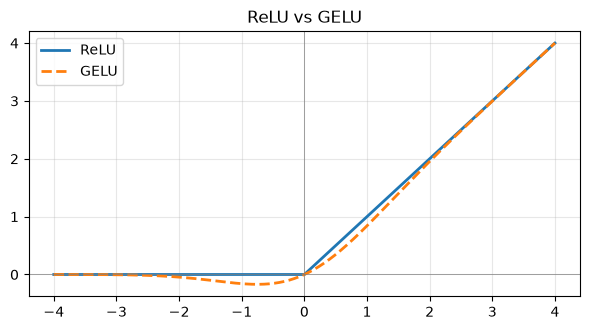

at z = -1: ReLU 0.0 | GELU -0.1587


In [4]:
z = torch.linspace(-4, 4, 401)
plt.figure(figsize=(6, 3.4))
plt.plot(z, F.relu(z), label="ReLU", lw=2); plt.plot(z, F.gelu(z), label="GELU", lw=2, ls="--")
plt.axhline(0, color="grey", lw=0.5); plt.axvline(0, color="grey", lw=0.5)
plt.legend(); plt.grid(alpha=0.3); plt.title("ReLU vs GELU"); plt.tight_layout(); plt.show()
print("at z = -1: ReLU", F.relu(torch.tensor(-1.)).item(), "| GELU", round(F.gelu(torch.tensor(-1.)).item(), 4))

For large positive inputs, the two are almost the same. The difference is near zero: ReLU has a sharp corner and outputs exactly 0 for every negative input, while GELU curves smoothly and lets small negative values through (at −1, ReLU gives 0.0 and GELU gives −0.1587). The smooth shape gives gradients for slightly negative inputs too, which tends to make training a little easier.

> **Check yourself 1.** The FFN never lets tokens exchange information. Why can a Transformer still produce contextual representations?

## 4. Residual Connections

A **residual connection** (or skip connection) adds a sub-layer's input to its output: instead of `x = f(x)`, we compute `x = x + f(x)`. The sub-layer only has to learn a **change** to apply to the vector, not a complete new vector.

This matters for two reasons.

- **Information is preserved.** The original token information flows straight up the stack. Each sub-layer adds to it rather than replacing it. This is the "residual stream" picture from Note 6.1.
- **Gradients have a direct path.** During backpropagation, the derivative of `x + f(x)` with respect to `x` includes a plain "+1" from the `x` term. So the gradient can flow from the loss back to the early layers along an uninterrupted highway, however deep the stack, instead of being multiplied through every sub-layer in turn, which, as Note 5.4 showed, makes gradients shrink.

Let's measure the second point. We build stacks of 1, 4, 12 and 24 blocks, with and without residual connections, pass a random input through, and measure the size of the gradient that arrives back at the input.

In [5]:
def input_gradient(depth, residual, seed=0):
    torch.manual_seed(seed)
    stack = nn.Sequential(*[Block(64, 4, residual=residual) for _ in range(depth)])
    x = torch.randn(4, 16, 64, requires_grad=True)
    stack(x).pow(2).mean().backward()
    return x.grad.norm().item()

print(f"{'blocks':>6} {'with residuals':>15} {'without':>12}")
for depth in [1, 4, 12, 24]:
    print(f"{depth:>6} {input_gradient(depth, True):>15.2e} {input_gradient(depth, False):>12.2e}")

blocks  with residuals      without
     1        3.33e-02     4.37e-03
     4        4.40e-02     5.11e-03
    12        1.03e-01     5.31e-03
    24        1.54e-01     5.26e-03


With residual connections, the gradient reaching the input is 3.33e-02 for one block and grows to 1.54e-01 for 24 blocks. Without them, it is much smaller at every depth, between 4.37e-03 and 5.31e-03, about 8 times smaller with one block and about 29 times smaller with 24. The deeper the stack, the more the residual path matters. In Section 7 we will see what this means for actual training.

> **Key terms**
> - **Residual (skip) connection:** adding a layer's input to its output, `x + f(x)`.
> - **Residual stream:** the sequence of token vectors that flows up through the model and that each sub-layer adds to.

> **Check yourself 2.** If a sub-layer learns to output all zeros, what does a block with residual connections do to its input?

## 5. Layer Normalisation

As a vector flows up through many blocks, each adding something to it, its numbers can drift to very different sizes. Large values make later layers behave erratically, and they make the best learning rate hard to choose. **Layer normalisation** (LayerNorm) keeps every token's vector at a standard scale.

For each token separately, LayerNorm:

1. computes the **mean** and **variance** of that token's numbers;
2. subtracts the mean and divides by the square root of the variance (plus a tiny number, 1e-5, to avoid dividing by zero), so the vector has mean 0 and standard deviation 1;
3. multiplies by a learnable **scale** and adds a learnable **shift**, so the model can choose a different scale if that helps.

Let's do it by hand for a 4-number vector:

In [6]:
v = torch.tensor([2.0, -1.0, 4.0, 3.0])
mean, var = v.mean(), v.var(unbiased=False)
by_hand = (v - mean) / torch.sqrt(var + 1e-5)
ln = nn.LayerNorm(4)
print("vector:", v.tolist(), "| mean", mean.item(), "| variance", var.item())
print("normalised by hand:", [round(t, 4) for t in by_hand.tolist()])
print("nn.LayerNorm:      ", [round(t, 4) for t in ln(v).tolist()])
print("learnable scale and shift start at:", ln.weight.tolist(), ln.bias.tolist())

vector: [2.0, -1.0, 4.0, 3.0] | mean 2.0 | variance 3.5
normalised by hand: [0.0, -1.6036, 1.069, 0.5345]
nn.LayerNorm:       [0.0, -1.6036, 1.069, 0.5345]
learnable scale and shift start at: [1.0, 1.0, 1.0, 1.0] [0.0, 0.0, 0.0, 0.0]


The vector `[2, −1, 4, 3]` has mean 2.0 and variance 3.5. Subtracting the mean and dividing by √3.5 gives `[0.0, −1.6036, 1.069, 0.5345]`, exactly what `nn.LayerNorm` returns. The learnable scale starts at 1 and the shift at 0, so at the start of training LayerNorm is pure standardisation.

Here is its effect on tokens of wildly different sizes:

In [7]:
torch.manual_seed(0)
xs = torch.randn(2, 5, 64) * torch.tensor([0.1, 1.0, 10.0, 100.0, 1000.0]).view(1, 5, 1)
out = nn.LayerNorm(64)(xs)
print("std of each token's 64 numbers before:", [round(t, 2) for t in xs[0].std(-1, unbiased=False).tolist()])
print("std of each token's 64 numbers after: ", [round(t, 2) for t in out[0].std(-1, unbiased=False).tolist()])
print("mean of each token after:              ", [round(abs(t), 4) for t in out[0].mean(-1).tolist()])

std of each token's 64 numbers before: [0.1, 1.03, 7.91, 85.4, 853.7]
std of each token's 64 numbers after:  [1.0, 1.0, 1.0, 1.0, 1.0]
mean of each token after:               [0.0, 0.0, 0.0, 0.0, 0.0]


Before normalisation, the five tokens' standard deviations range from 0.1 to 853.7. After it, every token has a standard deviation of 1.0 and a mean of 0.0. Whatever happens upstream, every sub-layer receives inputs at the same, predictable scale.

Note what LayerNorm normalises over: the 64 numbers **within one token**. It does not mix information between tokens or between examples in a batch, unlike the batch normalisation used in many CNNs. So it behaves identically in training and inference, and for any batch size.

> **Key terms**
> - **Layer normalisation:** rescaling each token's vector to mean 0 and standard deviation 1, followed by a learnable scale and shift.

> **Check yourself 3.** LayerNorm is applied to a token vector whose 64 numbers are all equal to 5. What problem arises, and how does the small constant 1e-5 help?

## 6. The Order of Operations Within a Transformer Block

There are two ways to combine normalisation with the residual connections.

- **Post-norm** (the original Transformer): transform, add, *then* normalise: `x = LayerNorm(x + sublayer(x))`. The normalisation sits on the residual stream itself.
- **Pre-norm** (most modern Transformers): normalise the sub-layer's *input*, transform, then add: `x = x + sublayer(LayerNorm(x))`. The residual stream is never normalised; it is a clean highway from bottom to top.

> 🖼 *IMAGE 6.4.2 — Post-Norm vs. Pre-Norm.* Two side-by-side vertical block diagrams on a white background. Left, titled "Post-norm (original)": the main stream goes up into a "+" that combines it with the output of a blue "attention" box, and then passes **through** a grey "LayerNorm" box sitting on the main stream itself, before the same pattern repeats with an orange "feed-forward" box. The LayerNorm boxes are drawn across the main path, with a small red note "every gradient must pass through the norms". Right, titled "Pre-norm (modern)": the main stream is an unbroken straight grey arrow from bottom to top; LayerNorm boxes sit only on the side branches, before the attention and feed-forward boxes, and the branches rejoin through "+" circles. A small green note reads "clean residual highway". Takeaway: pre-norm keeps the residual path free of normalisation, which makes deep stacks easier to train.

The difference looks cosmetic. Let's find out whether it is. We train a 6-block language model on Tiny Shakespeare, predicting the next character, with a fairly high learning rate of 0.01, for 250 steps, in three versions, each with two random seeds:

- post-norm, with no warmup;
- pre-norm, with no warmup;
- post-norm, with a 100-step **learning-rate warmup**: the learning rate starts near zero and rises linearly to 0.01 over the first 100 steps.

The training function also records the **gradient norm** at every step: the overall size of all the gradients combined, a useful health check.

In [8]:
PATH = "data/shakespeare/input.txt"
os.makedirs("data/shakespeare", exist_ok=True)
if not os.path.exists(PATH):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", PATH)
text = open(PATH, encoding="utf-8").read()
chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text]); train_ids = data[:int(0.9 * len(data))]
V, D, H, T, B = len(chars), 64, 4, 32, 32

class TinyLM(nn.Module):
    def __init__(self, n_layers, pre_norm, residual=True):
        super().__init__()
        self.tok, self.pos = nn.Embedding(V, D), nn.Embedding(T, D)
        self.blocks = nn.Sequential(*[Block(D, H, pre_norm=pre_norm, residual=residual) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(D) if pre_norm else nn.Identity()   # post-norm blocks already end with a norm
        self.head = nn.Linear(D, V)
    def forward(self, ids):
        return self.head(self.ln_f(self.blocks(self.tok(ids) + self.pos(torch.arange(ids.shape[1])))))

def train_run(pre_norm, lr, warmup, steps=250, n_layers=6, seed=0, residual=True):
    torch.manual_seed(seed)
    model = TinyLM(n_layers, pre_norm, residual)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    g = torch.Generator().manual_seed(seed)
    losses, grad_norms = [], []
    for step in range(steps):
        scale = min(1.0, (step + 1) / warmup) if warmup else 1.0      # linear warmup
        for group in opt.param_groups: group["lr"] = lr * scale
        starts = torch.randint(0, len(train_ids) - T - 1, (B,), generator=g)
        x = torch.stack([train_ids[s:s + T] for s in starts]); y = torch.stack([train_ids[s + 1:s + T + 1] for s in starts])
        loss = F.cross_entropy(model(x).view(-1, V), y.view(-1))
        opt.zero_grad(); loss.backward()
        grad_norms.append(torch.nn.utils.clip_grad_norm_(model.parameters(), float("inf")).item())   # measure only
        opt.step(); losses.append(loss.item())
    return losses, grad_norms

print("model parameters (6 blocks):", count(TinyLM(6, True)))

model parameters (6 blocks): 310465


In [9]:
runs = {}
for name, pre, warm in [("post-norm, no warmup", False, 0), ("pre-norm, no warmup", True, 0), ("post-norm, 100-step warmup", False, 100)]:
    for seed in [0, 1]:
        losses, gn = train_run(pre, lr=1e-2, warmup=warm, seed=seed)
        runs[(name, seed)] = (losses, gn)
        print(f"{name:<27} seed {seed}: loss over last 25 steps {np.mean(losses[-25:]):.3f} | largest gradient norm {max(gn):.1f}")

post-norm, no warmup        seed 0: loss over last 25 steps 3.341 | largest gradient norm 4.2


post-norm, no warmup        seed 1: loss over last 25 steps 3.317 | largest gradient norm 117.6


pre-norm, no warmup         seed 0: loss over last 25 steps 2.133 | largest gradient norm 1.3


pre-norm, no warmup         seed 1: loss over last 25 steps 2.146 | largest gradient norm 1.1


post-norm, 100-step warmup  seed 0: loss over last 25 steps 2.229 | largest gradient norm 1.4


post-norm, 100-step warmup  seed 1: loss over last 25 steps 2.232 | largest gradient norm 1.6


The results split sharply.

- **Post-norm, no warmup** fails on both seeds: its loss is stuck at 3.341 and 3.317. With seed 1, its gradient norm spiked to 117.6 at one point.
- **Pre-norm, no warmup** trains well on both seeds: 2.133 and 2.146.
- **Post-norm with warmup** trains on both seeds too, 2.229 and 2.232, although a little behind pre-norm after the same number of steps.

What does a loss of about 3.3 mean? Let's compute two reference points:

In [10]:
counts = torch.bincount(train_ids, minlength=V).float(); p = counts / counts.sum()
unigram = -(p * p.log()).sum().item()
print(f"loss of always predicting overall character frequencies: {unigram:.3f}")
print(f"loss of a uniform guess, ln({V}): {math.log(V):.3f}")

loss of always predicting overall character frequencies: 3.309
loss of a uniform guess, ln(65): 4.174


A model that ignores the input and always predicts the overall frequency of each character (how often `e`, space, `t` and so on appear) gets a loss of 3.309. A completely uniform guess gets ln(65) = 4.174. The failed post-norm runs, at 3.317 and 3.341, have collapsed to the character-frequency baseline: the model has learned how common each character is, and nothing else. The plot shows it happening.

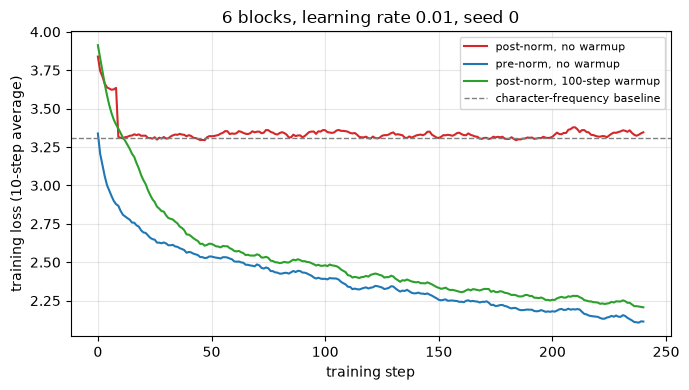

In [11]:
plt.figure(figsize=(7, 4))
smooth = lambda a: np.convolve(a, np.ones(10) / 10, mode="valid")
for name, c in [("post-norm, no warmup", "tab:red"), ("pre-norm, no warmup", "tab:blue"), ("post-norm, 100-step warmup", "tab:green")]:
    plt.plot(smooth(runs[(name, 0)][0]), color=c, label=name)
plt.axhline(unigram, color="grey", ls="--", lw=1, label="character-frequency baseline")
plt.xlabel("training step"); plt.ylabel("training loss (10-step average)")
plt.title("6 blocks, learning rate 0.01, seed 0"); plt.grid(alpha=0.3); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

The post-norm run (red) drops quickly, then falls onto the dashed baseline within about ten steps and never leaves it. The pre-norm run (blue) and the warmed-up post-norm run (green) keep improving throughout.

Why does post-norm break? In post-norm, every gradient travelling down the residual stream must pass through a LayerNorm in every block, and early in training, with random weights and a large learning rate, the first updates can be large enough to knock the model into a state from which it does not recover. **Warmup** avoids those damaging first steps by keeping the early updates small, and **pre-norm** avoids the problem in the first place by keeping the residual path free of normalisation.

This is why almost every modern Transformer uses pre-norm, and why warmup is standard practice whenever post-norm (or any fragile setup) is used. The original Transformer paper also trained with a learning-rate warmup.

> **Common mistake:** concluding that a model or dataset "doesn't work" because a loss curve flattens at a baseline. A loss stuck at the character-frequency (or class-frequency) baseline usually means training has collapsed, often because of an unstable setup. Before changing anything else, compare against simple baselines, then try a lower learning rate, warmup or pre-norm.

> **Key terms**
> - **Post-norm / pre-norm:** layer normalisation applied after the residual addition / to each sub-layer's input.
> - **Learning-rate warmup:** gradually increasing the learning rate from near zero at the start of training.
> - **Gradient norm:** the overall size of all gradients combined; a sudden spike is a warning sign.
> - **Training collapse:** training that gets stuck at a trivial solution, such as predicting only class frequencies.

> **Check yourself 4.** A colleague's post-norm Transformer is stuck at a loss equal to the character-frequency baseline. Suggest two changes, each supported by the experiment above.

## 7. Stacking Transformer Blocks: Why Depth and Residual Connections Matter

A single block lets each token gather information once and process it once. Stacking blocks lets the model **build on what earlier blocks found**. One block might connect each character to the one before it; a later block can then use that to recognise whole words; later still, which speaker is talking. Each block's attention works on vectors that already contain context from the blocks below, so the reach and complexity of what the model can represent grows with depth: the same hierarchy idea as CNN layers in Note 5.2.

Depth costs parameters, but each block adds the same amount:

In [12]:
for d in [1, 3, 6, 12, 24]:
    m = TinyLM(d, True)
    print(f"{d:>2} blocks: {count(m):>9,} parameters")

 1 blocks:    60,545 parameters
 3 blocks:   160,513 parameters
 6 blocks:   310,465 parameters


12 blocks:   610,369 parameters


24 blocks: 1,210,177 parameters


Each extra block adds 49,984 parameters (for example, 60,545 for one block, 160,513 for three and 310,465 for six; the rest is the embeddings, final norm and output head). Large language models stack dozens of much wider blocks.

But depth only helps if the stack can be trained. In Section 4 we saw that removing residual connections makes the gradient reaching the input much smaller. Here is what that means in practice: the same 6-block pre-norm model, trained for 200 steps at a learning rate of 0.003, with and without residual connections.

In [13]:
for residual in [True, False]:
    losses, _ = train_run(True, lr=3e-3, warmup=0, steps=200, n_layers=6, residual=residual)
    print(f"6 pre-norm blocks, {'with' if residual else 'WITHOUT'} residual connections: "
          f"loss over last 25 steps {np.mean(losses[-25:]):.3f}")

6 pre-norm blocks, with residual connections: loss over last 25 steps 2.267


6 pre-norm blocks, WITHOUT residual connections: loss over last 25 steps 3.296


With residual connections, the model reaches a loss of 2.267. Without them, it reaches 3.296: almost exactly the character-frequency baseline of 3.309. Without the residual highway, this 6-block model learns essentially nothing about context in 200 steps. Residual connections are not an optional refinement; they are what makes a deep Transformer trainable.

> **Check yourself 5.** Why might a 1-block model without residual connections still train reasonably, while a 6-block model without them fails?

## Putting It All Together

A **Transformer block** takes `(batch, tokens, d_model)` and returns the same shape, through two sub-layers:

```
x = x + attention(layer_norm_1(x))
x = x + feed_forward(layer_norm_2(x))
```

**Attention** (16,640 parameters in our block) gathers information between tokens. The **feed-forward network** (33,088 parameters) processes each token separately, expanding to 256 numbers, applying GELU and contracting again. **Residual connections** add each sub-layer's output to its input, preserving information and giving gradients a direct path: without them, the gradient reaching the input was about 29 times smaller in a 24-block stack, and a 6-block model got stuck at 3.296, the character-frequency baseline. **Layer normalisation** rescales each token to mean 0 and standard deviation 1, whatever its size was before.

The order of these ingredients matters. At a learning rate of 0.01, **post-norm** blocks collapsed to the baseline on both seeds (3.341 and 3.317), while **pre-norm** blocks trained (2.133 and 2.146), and a 100-step **warmup** rescued post-norm (2.229 and 2.232). That is why our model, like most modern ones, uses pre-norm.

Stacking blocks adds 49,984 parameters each and lets later blocks build on what earlier ones found. In Note 6.5 we stack three of them into a complete language model.

> 🖼 *IMAGE 6.4.3 — Four Ingredients, Four Jobs.* A 2×2 grid of illustrated cards on a white background. Card 1, "Attention": several small circles (tokens) connected by curved lines of varying thickness, caption "gather: tokens exchange information". Card 2, "Feed-forward": a single token vector expanding into a wide layer and contracting again, caption "process: each token thinks on its own". Card 3, "Residual connection": a straight highway arrow with a side road merging back via a "+", caption "preserve: add changes, keep the original; gradients flow straight through". Card 4, "Layer norm": three bars of very different heights being resized to the same height, caption "stabilise: every token at a standard scale". Takeaway: each ingredient of the block does a distinct job, and the block needs all four.

## Summary

- A Transformer block has two sub-layers, attention and feed-forward, each with layer normalisation and a residual connection. Its input and output shapes are the same.
- **Attention** gathers information between tokens; the **feed-forward network** processes each token separately (64 → 256 → 64 with GELU) and holds most of the block's parameters.
- **Residual connections** (`x + f(x)`) preserve information and give gradients a direct path; without them, gradients reaching the input were far smaller and a 6-block model failed to learn (3.296 vs. 2.267).
- **Layer normalisation** rescales each token's vector to mean 0 and standard deviation 1, with a learnable scale and shift.
- **Pre-norm** (normalise each sub-layer's input) trains reliably; **post-norm** collapsed at a high learning rate unless the learning rate was **warmed up**.
- A loss stuck at the character-frequency baseline (3.309 here) is a sign of training collapse.
- Stacking blocks adds 49,984 parameters each and lets later blocks build on earlier ones.

## Glossary

| Term | Meaning |
|---|---|
| Transformer block | Attention and feed-forward sub-layers, each with layer norm and a residual connection. |
| Sub-layer | One of the two parts of a block: attention or feed-forward. |
| Feed-forward network (FFN) | A two-layer MLP applied to each token separately. |
| GELU | A smooth activation function similar to ReLU, used in most modern Transformers. |
| Residual (skip) connection | Adding a sub-layer's input to its output: `x + f(x)`. |
| Residual stream | The token vectors flowing up the model, which each sub-layer adds to. |
| Layer normalisation | Rescaling each token's vector to mean 0 and standard deviation 1, plus a learnable scale and shift. |
| Post-norm | Normalising after the residual addition (original Transformer). |
| Pre-norm | Normalising each sub-layer's input (modern Transformers). |
| Learning-rate warmup | Raising the learning rate gradually at the start of training. |
| Gradient norm | The overall size of all gradients combined. |
| Training collapse | Training stuck at a trivial solution, such as predicting only frequencies. |
| Character-frequency baseline | The loss of always predicting each character's overall frequency. |

## Answers to Check Yourself

**1.** Because the attention sub-layer, which comes first in every block, has already mixed information from other tokens into each token's vector. The FFN then processes that context-rich vector. Attention gathers; the FFN processes what was gathered.

**2.** It passes the input through unchanged: `x + 0 = x`. This is one reason residual blocks are easy to train: a block that has not learned anything useful yet does no harm.

**3.** All 64 numbers equal the mean, so the variance is 0, and dividing by √0 would mean dividing by zero. Adding 1e-5 inside the square root keeps the division safe; the result is simply a vector of zeros (before the learnable shift).

**4.** Either switch to pre-norm blocks, which trained well with the same learning rate, or add a learning-rate warmup, which rescued post-norm on both seeds. Lowering the learning rate is a third reasonable option.

**5.** With one block, the gradient has only one sub-layer pair to pass through, so enough of it reaches the embeddings. With six blocks and no residual path, the gradient must pass through twelve sub-layers in turn and arrives much weaker, so the early layers barely learn, and the input information is replaced rather than refined at every step.